# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_:
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how both Euler's method and Runge-Kutta method work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Delos Santos, Mico
- _Student No._: 2024-35117
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure

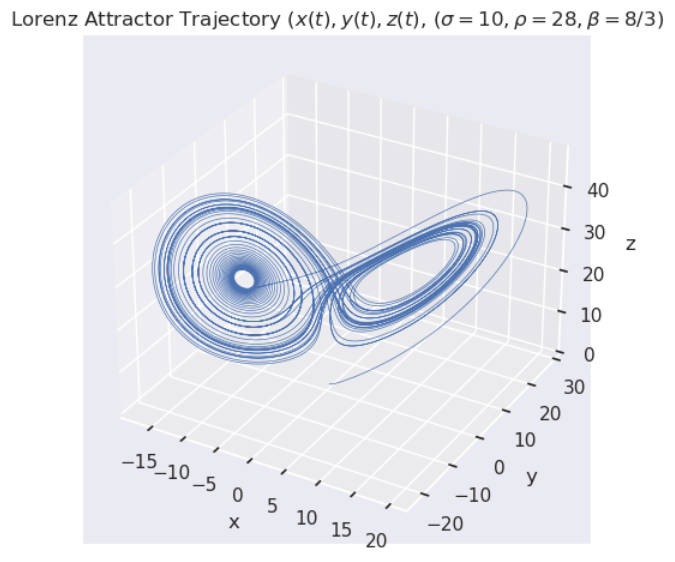
Figure 1.01. 3D Lorenz attractor

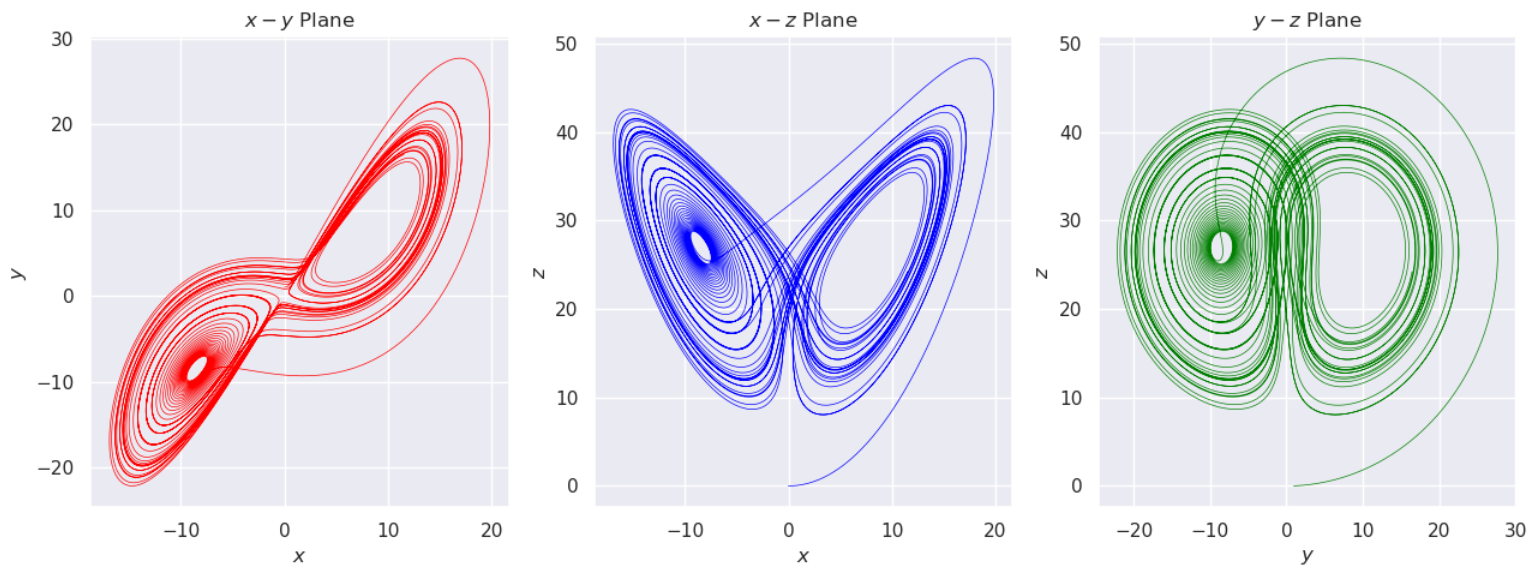
Figure 1.02. 2D Lorenz attractor-Butterfly

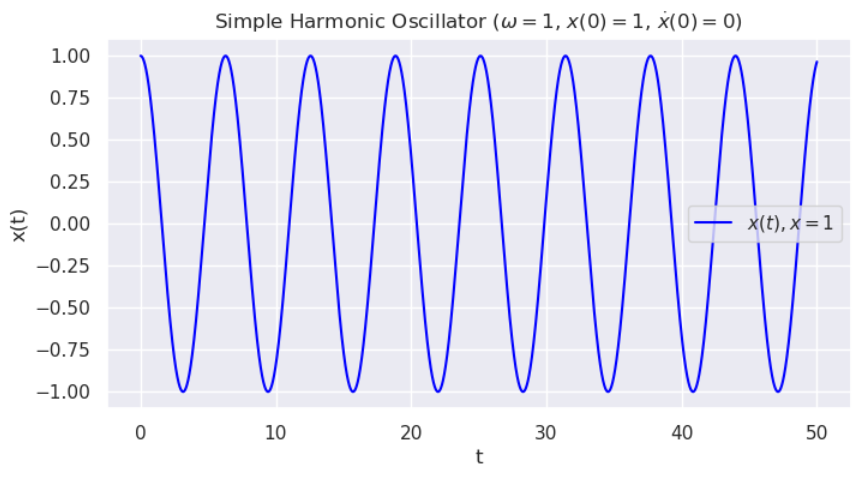
Figure 1a. SHO for $x=1$

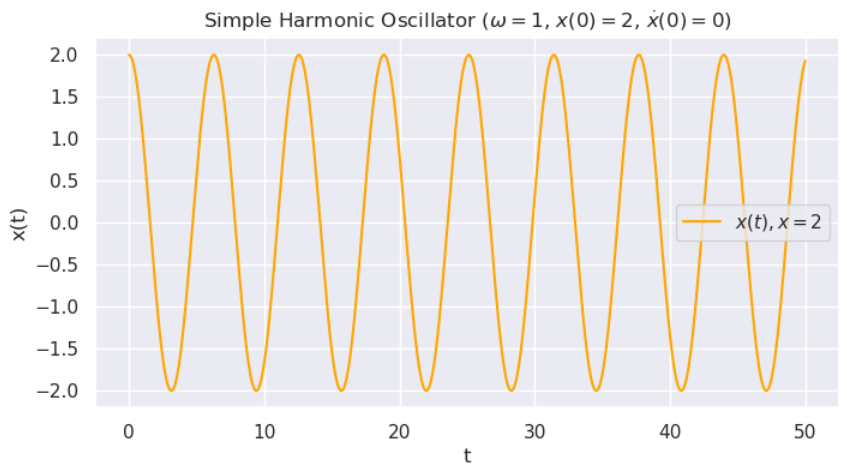
Figure 1b. SHO for $x=2$

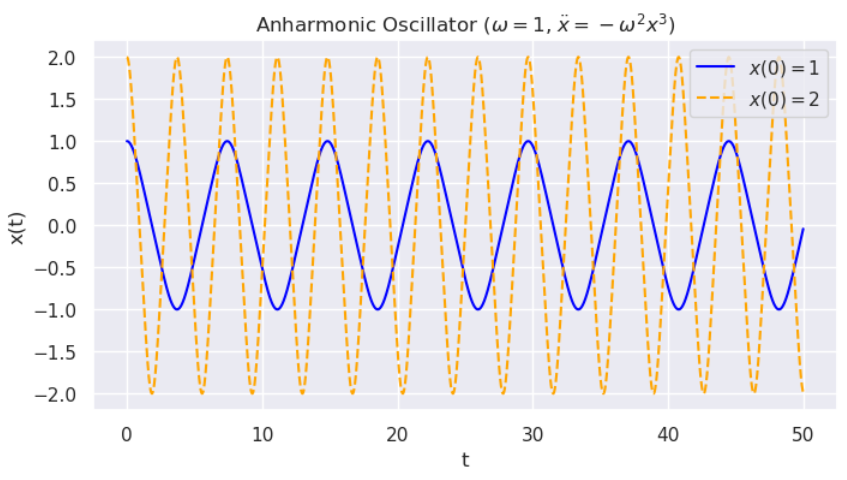
Figure 1c. Anharmonic Oscillator

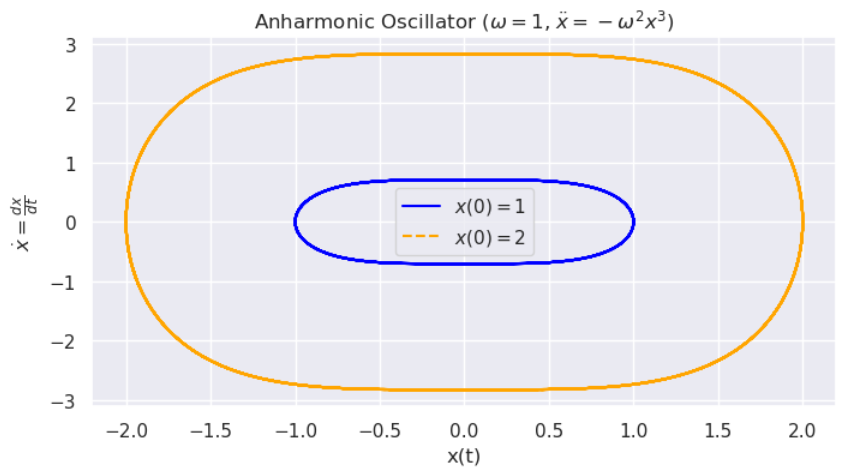
Figure 1d. Anharmonic Oscillator - Phase Space

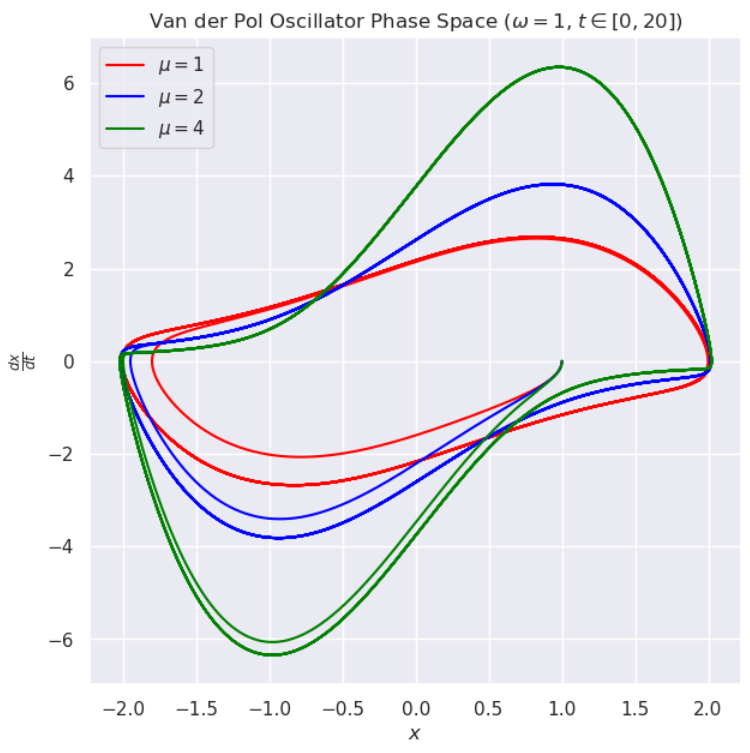
Figure 2. Van der Pol - Phase Space

### Report discussion

The Lorenz attractor, that is $(\sigma, \rho, \beta) = (10, 28, 8/3)$ shows the deterministic chaos in the form of a butterfly as shown in Fig. 1.01 and 1.02. It started at some point bu never goes back to that same point, so we do not have a closed trajectory.

For Fig. 1a and 1b, we see the simple harmonic oscillator (SHO) that produces sinusoidal oscillations that changes its amplitude depending on the value of $x$. In the problem, we consider $x(0)=1$ and $x(0)=2$. Amplitude may change but the period left unchanged for $\omega=1$.

For Fig. 1c, we see the anharmonic oscillator where the DE becomes proportional to $x^3$ instead of just $x$ of the SHO. We still connsider the same conditions and same amplitudes. However, we see that the period shortens or the oscillation frequency increases over the same intervals of $t\in(0,50)$. For this system, we also look at their phase space as shown in Fig. 1d. The trajectory of anharmonic oscillator is a closed conservative loops, but the higher amplitude has a greater loop that expands greatly for both $x$ and $\ddot{x}$.

For Fig. 2, we see the Van der Pol oscillator. The same conditions are used in this problem but we have a new parameter $\mu$ which we consider three values (1, 2, and 4). As $\mu$ increases, also increases the peak, that is the expansion of $\ddot{x}$ from both negative and positive values in its phase space.

We now compare the twp PDE methods, the Euler's and Runge-Kutta (RK4). For a system $\ddot{y}=\frac{dy}{dt}=f(t,y)$ with a step size $h$, we only use the slope evaluated at the start of the interval for Euler's method, where $h$ is constant throughout. However in RK4, we have four points which sampled the slope for start and endpoint respectively, and two in the midpoint. This comparison clearly shows the bigger error when using Euler's method. For faster computation however, Euler's win, but in larger stability and wide range RK4 wins the battle.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{d \theta}{dt} &= \omega \\
\frac{d \omega}{dt} &= -\frac{g}{l}\sin(\theta)
\end{align}

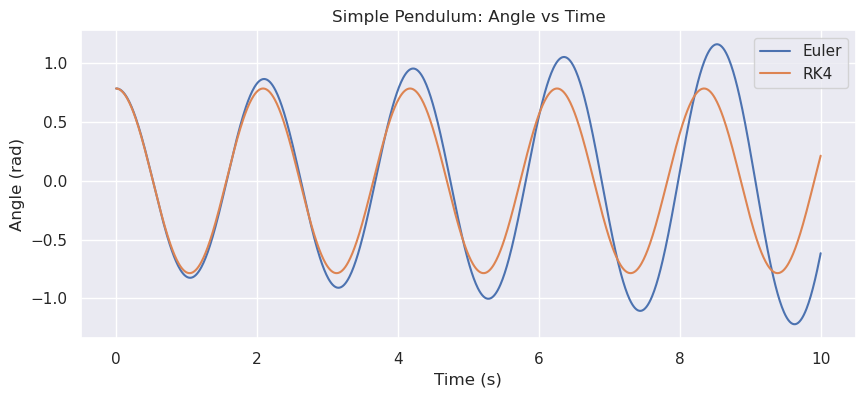

In [ ]:
# practice mode

# global constants
g = 9.81
l = 1.0

def pendulum_ode(t, R):
    # R is a vector containing the two variables theta, omega

    # unpack R
    # define f0
    # define f1
    return np.array([f0, f1])


# given time interval from 0 to 10 seconds sampled at 1000 pts, define a, b, n

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = np.array([, ]) # theta0, omega0

t, Y_euler = eulergen(pendulum_ode, a, b, n, yinit)
t, Y_rk4 = rk4gen(pendulum_ode, a, b, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

In [25]:
sigma = 10
rho = 28
beta = 8/3
t = np.linspace(0, 50, 1000)

def fs(t, yvals):
  x, y, z = yvals
  dx = sigma * (y - x)
  dy = (rho * x) - y - (x * z)
  dz = (x * y) - (beta * z)
  return np.array([dx, dy, dz])

def rk4gen(fs, a, b, n, yinits):
    h = (b-a)/(n-1)
    ts = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)

    for j,t in enumerate(ts):
        ys[j,:] = yvals
        k0 = h * fs(t, yvals)
        k1 = h * fs(t+h/2, yvals+k0/2)
        k2 = h * fs(t+h/2, yvals+k1/2)
        k3 = h * fs(t+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return ts, ys

a, b, n = 0, 50, 50000
yinits = np.array([0.0, 1.0, 0.0])  #(x,y,z) = (0,1,0)
ts, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [9.94584648e-03 9.99139930e-01 4.97462907e-06]
 [1.97855568e-02 9.98557575e-01 1.98005084e-05]
 ...
 [1.14112026e+01 1.64115270e+01 2.39782878e+01]
 [1.14611025e+01 1.64403872e+01 2.41020347e+01]
 [1.15107868e+01 1.64679902e+01 2.42265927e+01]]


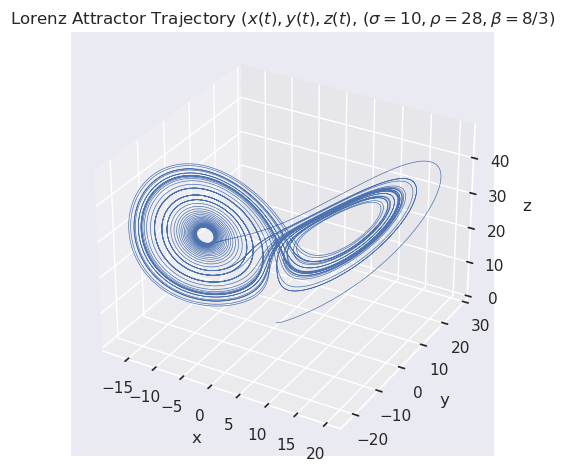

In [26]:
#separate/unpack solution columns from rk4gen output (ts, ys)
x = ys[:, 0]
y = ys[:, 1]
z = ys[:, 2]

fig = plt.figure(figsize=(7, 5.5))
ax3d = fig.add_subplot(111, projection="3d")
ax3d.plot(ys[:, 0], ys[:, 1], ys[:, 2], linewidth=0.5)
ax3d.set_title(r"Lorenz Attractor Trajectory $(x(t), y(t), z(t)$, ($\sigma=10, \rho=28, \beta=8/3$)")
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

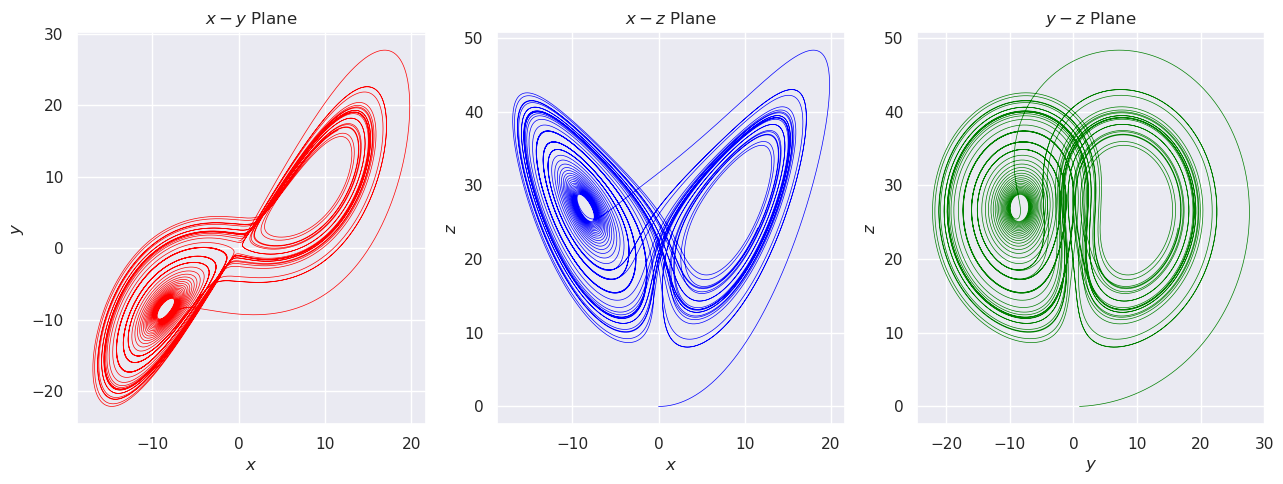

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(13, 5))

#x-y projection
axs[0].plot(x, y, color='red', linewidth=0.5)
axs[0].set_title("$x - y$ Plane")
axs[0].set_xlabel("$x$")
axs[0].set_ylabel("$y$")

#x-z projection
axs[1].plot(x, z, color='blue', linewidth=0.5)
axs[1].set_title("$x - z$ Plane")
axs[1].set_xlabel("$x$")
axs[1].set_ylabel("$z$")

#y-z projection
axs[2].plot(y, z, color='green', linewidth=0.5)
axs[2].set_title("$y - z$ Plane")
axs[2].set_xlabel("$y$")
axs[2].set_ylabel("$z$")

plt.tight_layout()
plt.show()

#### Problem 1 code summary

We define all of the parameters first, then define the function $fs$. We then make use of the RK4 algorithm and applying the initial condition. Lastly, separate the solution column respectively so that we can plot the Lorenz DE in 2D.

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

In [63]:
omega = 1

def fs(t, yvals):
  y0, y1 = yvals
  dx = y1
  dy = -omega**2 * y0
  return np.array([dx, dy])

def rk4gen(fs, a, b, n, inits):
    h = (b-a)/(n-1)
    ts = a + np.arange(n)*h
    ys = np.zeros((n, inits.size))
    yvals = np.copy(inits)

    vals = np.copy(inits)
    for j,t in enumerate(ts):
        ys[j,:] = yvals
        k0 = h * fs(t, yvals)
        k1 = h * fs(t+h/2, yvals+k0/2)
        k2 = h * fs(t+h/2, yvals+k1/2)
        k3 = h * fs(t+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return ts, ys

a, b, n = 0, 50, 50000
inits_a = np.array([1.0, 0.0])   #x(0) = 1, dx/dt(0) = 0
ts_a, ys_a = rk4gen(fs,a,b,n,inits_a)
print(ys_a)

[[ 1.          0.        ]
 [ 0.9999995  -0.00100002]
 [ 0.999998   -0.00200004]
 ...
 [ 0.96443934  0.2643043 ]
 [ 0.96470317  0.26333971]
 [ 0.96496603  0.26237485]]


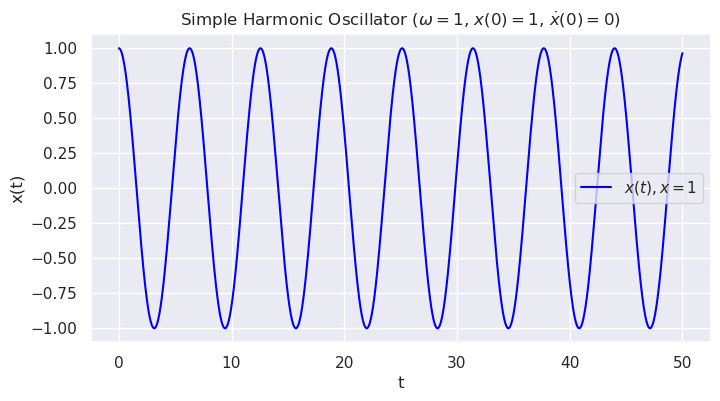

In [64]:
plt.figure(figsize=(8, 4))
plt.plot(ts, ys_a[:, 0], color='blue', label=r"$x(t), x=1$")
plt.title(r"Simple Harmonic Oscillator ($\omega = 1$, $x(0) = 1$, $\dot{x}(0) = 0$)")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.legend()
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

[[ 2.          0.        ]
 [ 1.999999   -0.00200004]
 [ 1.999996   -0.00400008]
 ...
 [ 1.92887868  0.5286086 ]
 [ 1.92940633  0.52667942]
 [ 1.92993206  0.52474971]]


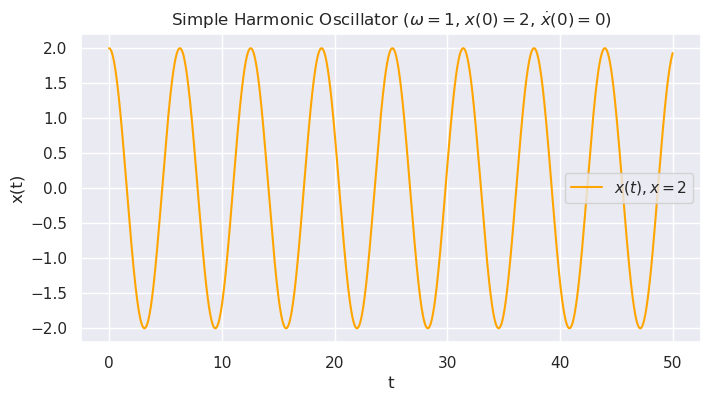

In [66]:
#x = 2

inits_b = np.array([2.0, 0.0])   #x(0) = 1, dx/dt(0) = 0
ts_b, ys_b = rk4gen(fs,a,b,n,inits_b)
print(ys_b)

plt.figure(figsize=(8, 4))
plt.plot(ts, ys_b[:, 0], color='orange', label=r"$x(t), x=2$")
plt.title(r"Simple Harmonic Oscillator ($\omega = 1$, $x(0) = 2$, $\dot{x}(0) = 0$)")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.legend()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt^2} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

[[ 1.          0.        ]
 [ 0.9999995  -0.00100002]
 [ 0.999998   -0.00200004]
 ...
 [-0.04385215  0.70710547]
 [-0.04314503  0.70710556]
 [-0.04243791  0.70710563]]
[[ 2.          0.        ]
 [ 1.999996   -0.00800014]
 [ 1.999984   -0.01600019]
 ...
 [-1.9846748  -0.49234062]
 [-1.98516324 -0.48452006]
 [-1.98564385 -0.47669378]]


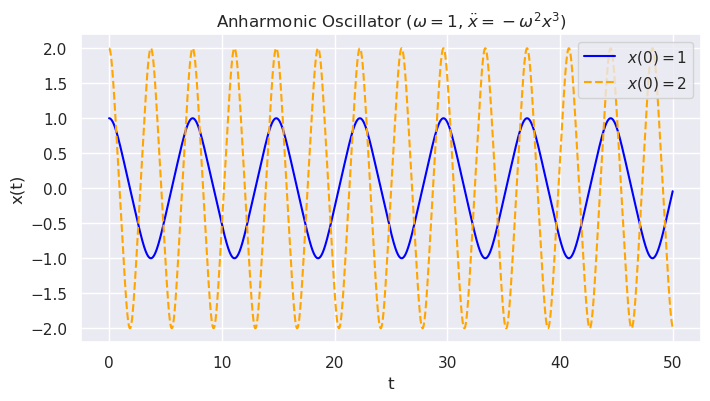

In [58]:
omega = 1

def fs(t, yvals):
  y0, y1 = yvals
  dx = y1
  dy = -omega**2 * y0**3
  return np.array([dx, dy])

def rk4gen(fs, a, b, n, inits):
    h = (b-a)/(n-1)
    ts = a + np.arange(n)*h
    ys = np.zeros((n, inits.size))
    yvals = np.copy(inits)

    vals = np.copy(inits)
    for j,t in enumerate(ts):
        ys[j,:] = yvals
        k0 = h * fs(t, yvals)
        k1 = h * fs(t+h/2, yvals+k0/2)
        k2 = h * fs(t+h/2, yvals+k1/2)
        k3 = h * fs(t+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return ts, ys

a, b, n = 0, 50, 50000
inits_c1 = np.array([1.0, 0.0])   #x(0) = 1, dx/dt(0) = 0
inits_c2 = np.array([2.0, 0.0])   #x(0) = 2, dx/dt(0) = 0
ts_c1, ys_c1 = rk4gen(fs,a,b,n,inits_c1)
ts_c2, ys_c2 = rk4gen(fs,a,b,n,inits_c2)
print(ys_c1)
print(ys_c2)

plt.figure(figsize=(8, 4))
plt.plot(ts_c1, ys_c1[:, 0], color='blue', label=r"$x(0) = 1$")
plt.plot(ts_c2, ys_c2[:, 0], '--', color='orange', label=r"$x(0) = 2$")
plt.title(r"Anharmonic Oscillator ($\omega = 1$, $\ddot{x} = -\omega^2 x^3$)")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.legend()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

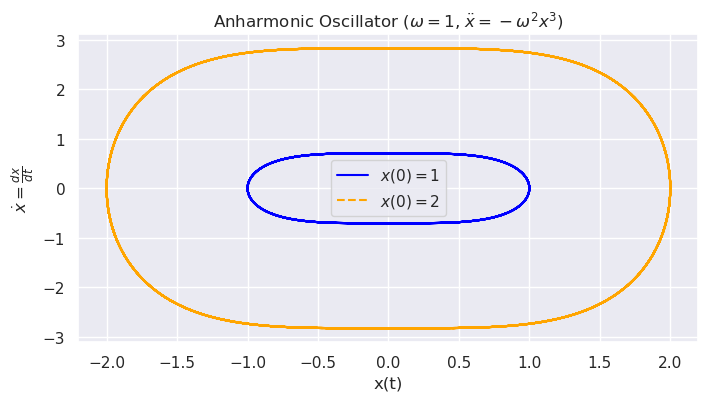

In [72]:
plt.figure(figsize=(8, 4))
plt.plot(ys_c1[:, 0], ys_c1[:, 1], color="blue", label=r"$x(0) = 1$")
plt.plot(ys_c2[:, 0], ys_c2[:, 1], "--", color="orange", label=r"$x(0) = 2$")
plt.title(r"Anharmonic Oscillator ($\omega = 1$, $\ddot{x} = -\omega^2 x^3$)")
plt.xlabel("x(t)")
plt.ylabel(r'$\dot{x}=\frac{dx}{dt}$')
plt.grid(True)
plt.legend()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

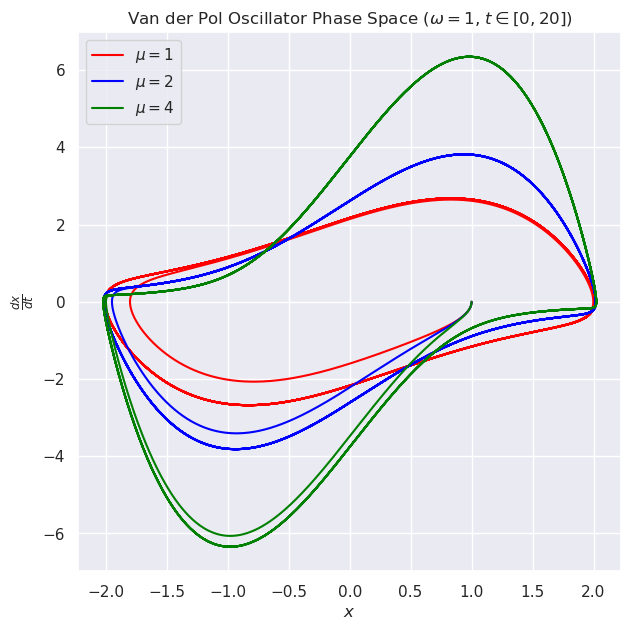

In [86]:
#same
omega = 1

#lhs = \ddot{x}, rhs = others
def fs(t, yvals):
  y0, y1 = yvals
  dx = y1
  dy = mu * (1 - y0**2) * y1 - y0
  return np.array([dx, dy])

def rk4gen(fs, a, b, n, inits):
    h = (b-a)/(n-1)
    ts = a + np.arange(n)*h
    ys = np.zeros((n, inits.size))
    yvals = np.copy(inits)

    vals = np.copy(inits)
    for j,t in enumerate(ts):
        ys[j,:] = yvals
        k0 = h * fs(t, yvals)
        k1 = h * fs(t+h/2, yvals+k0/2)
        k2 = h * fs(t+h/2, yvals+k1/2)
        k3 = h * fs(t+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return ts, ys

#same conditions
a, b, n = 0, 50, 50000
inits = np.array([1.0, 0.0])   #x(0) = 1, dx/dt(0) = 0

#new, computes per mu's
mu = 1
ts_e1, ys_e1 = rk4gen(fs, a, b, n, inits)

mu = 2
ts_e2, ys_e2 = rk4gen(fs, a, b, n, inits)

mu = 4
ts_e4, ys_e4 = rk4gen(fs, a, b, n, inits)

plt.figure(figsize=(7, 7))
plt.plot(ys_e1[:, 0], ys_e1[:, 1], color='red', label=r"$\mu = 1$")
plt.plot(ys_e2[:, 0], ys_e2[:, 1], color='blue', label=r"$\mu = 2$")
plt.plot(ys_e4[:, 0], ys_e4[:, 1], color='green',label=r"$\mu = 4$")
plt.title(r"Van der Pol Oscillator Phase Space ($\omega = 1$, $t \in [0, 20]$)")
plt.xlabel(r"$x$")
plt.ylabel(r"$\frac{dx}{dt}$")
plt.grid(True)
plt.legend()
plt.show()

#### Problem 2 code summary

Same with the first problem, define the function, use RK4, and define parameters respectively as asked by each sub-problem from a. to e. so that we can 'recycle' the code. For e., redefine the fs for the given Van der Pol DE, and do the same thing.

---
## Section 3: Notes

In [ ]:
# forward Euler's method

def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

In [ ]:
# 2nd order Runge-Kutta method

def rk2(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k1 = h*f(x, y)
        k2 = h*f(x+0.5*h, y+0.5*k1)
        y += k2
    return xs, ys

In [ ]:
# 4th order Runge-Kutta method (1 equation only, use the code below for simultaneous eqns)

def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

[19.53       19.59919146 19.67369182 19.75226242 19.83257721]
[19.53       19.60199388 19.6790241  19.75924981 19.83967675]
[19.53       19.60202244 19.67902463 19.75914998 19.83939363]


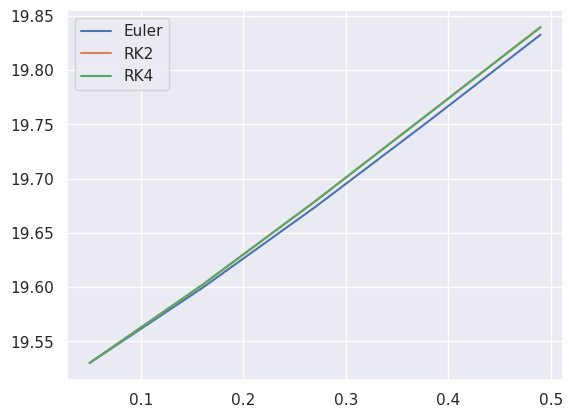

In [ ]:
# execution
a, b, n, yinit = 0.05, 0.49, 5, 19.53

def f(x,y):
    ...

xs, ys = euler(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='Euler')
xs, ys = rk2(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK2')
xs, ys = rk4(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK4')
plt.legend()
plt.show()

#### Solving IVP problem of 2 simultaneous ODEs

In [ ]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])

def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [ ]:
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

### Plotting

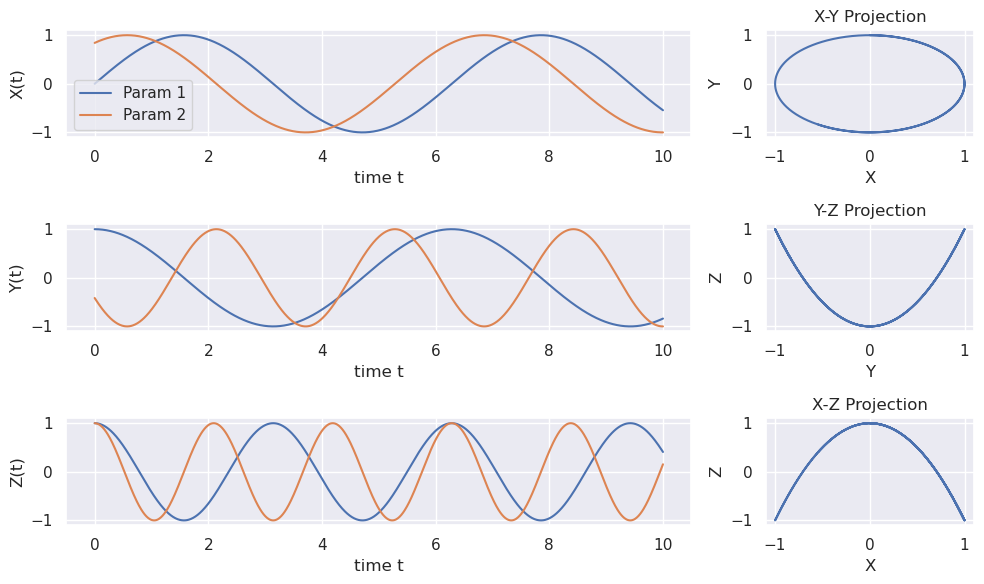

In [ ]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)

# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()